In [1]:
import numpy as np

X = np.array([
    1, 2, 3, 4, 5, 6, 7, 8
], dtype = np.float32)

y = np.array([
    35, 40, 45, 50, 55, 65, 70, 80
], dtype=np.float32)

In [2]:
# Inspect the data
print(X)

[1. 2. 3. 4. 5. 6. 7. 8.]


In [3]:
print(y)

[35. 40. 45. 50. 55. 65. 70. 80.]


In [4]:
# install pytorch
!pip install torch

Defaulting to user installation because normal site-packages is not writeable


In [5]:
import torch

In [6]:
# Convert Numpy arrays to tensors
X = torch.tensor(X)
y = torch.tensor(y)

In [7]:
print(X)
print(y)

tensor([1., 2., 3., 4., 5., 6., 7., 8.])
tensor([35., 40., 45., 50., 55., 65., 70., 80.])


In [8]:
# Tensor Example
x = torch.tensor(5.0, requires_grad = True)

y = x ** 2

y.backward()

print(x.grad)

tensor(10.)


In [9]:
print(X)
print(y)

tensor([1., 2., 3., 4., 5., 6., 7., 8.])
tensor(25., grad_fn=<PowBackward0>)


In [10]:
w = torch.tensor(
    0.0,
    requires_grad = True
)


In [11]:
b = torch.tensor(
    0.0, 
    requires_grad = True
)

In [12]:
# Def model
def model(x):
    return w*x + b

In [13]:
predictions = model(X)

print(predictions)

tensor([0., 0., 0., 0., 0., 0., 0., 0.], grad_fn=<AddBackward0>)


In [14]:
# Mean Squared Error
loss_function = torch.nn.MSELoss()

loss = loss_function(predictions, y)

print(loss)

tensor(625., grad_fn=<MseLossBackward0>)


C:\Users\Admin\AppData\Roaming\Python\Python312\site-packages\torch\nn\modules\loss.py:630: UserWarning: Using a target size (torch.Size([])) that is different to the input size (torch.Size([8])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


# BackPropagation

In [15]:
print(loss)

tensor(625., grad_fn=<MseLossBackward0>)


In [16]:
learning_rate = 0.01

In [17]:
print(w.grad)

None


In [18]:
print(b.grad)

None


In [19]:
# Update the parameters
with torch.no_grad():

    w = learning_rate * w.grad
    b = learning_rate * b.grad

TypeError: unsupported operand type(s) for *: 'float' and 'NoneType'

In [20]:
w

tensor(0., requires_grad=True)

# Train the model

In [21]:
import torch

X = torch.tensor(
    [1, 2, 3, 4, 5, 6, 7, 8],
    dtype = torch.float32
)

y = torch.tensor(
    [35, 40, 50, 55, 65, 70, 80, 85],
    dtype = torch.float32
)

w = torch.tensor(0.0, requires_grad = True)
b = torch.tensor(0.0, requires_grad = True)

learning_rate = 0.001
loss_function = torch.nn.MSELoss()

for epoch in range(1000):

    #forward pass
    predictions = w * X + b

    # Calculate loss
    loss = loss_function(predictions, y)

    # Backpropagation
    loss.backward()

    # Update parameters
    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    # Reset the gradients
    w.grad.zero_()
    b.grad.zero_()

    if epoch % 100 == 0:
        print(
            f"Epoch {epoch}, Loss: {loss.item():.4f}"
        )
        

Epoch 0, Loss: 3887.5000
Epoch 100, Loss: 117.4806
Epoch 200, Loss: 108.5070
Epoch 300, Loss: 100.2926
Epoch 400, Loss: 92.7086
Epoch 500, Loss: 85.7069
Epoch 600, Loss: 79.2425
Epoch 700, Loss: 73.2743
Epoch 800, Loss: 67.7643
Epoch 900, Loss: 62.6771


# Making Predictions

In [22]:
hours = torch.tensor(9.0)

prediction = w * hours + b

print(prediction)

tensor(103.1646, grad_fn=<AddBackward0>)


# A simple Feed forward neural network

In [22]:
import torch
import torch.nn as nn

class NeuralNetwork(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(1, 16),

            nn.ReLU(),

            nn.Linear(16, 16),

            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)

In [23]:
model = NeuralNetwork()

In [26]:
print(model)

<function model at 0x000001D8232ACFE0>


In [27]:
optimizer = torch.optim.SGD(
    model.parameters(),
    lr = 0.001
)

AttributeError: 'function' object has no attribute 'parameters'

In [28]:
X.shape

torch.Size([8])

In [29]:
# reshape x
X = X.reshape(-1, 1)

In [30]:
X.shape

torch.Size([8, 1])

In [31]:
X = torch.tensor(
    [1, 2, 3, 4, 5, 6, 7, 8],
    dtype = torch.float32
).reshape(-1, 1)

y = torch.tensor(
    [35, 40, 50, 55, 65, 70, 80, 85],
    dtype = torch.float32
).reshape(-1, 1)

In [32]:
# Training Loop

for epoch in range(1000):
    # forward pass
    predictions = model(X)
    #Loss 
    loss = loss_function(predictions, y)
    # Clear gradients
    optimizer.zero_grad()
    #Backpropagation
    loss.backward()
    #Update param
    optimizer.step()

    if epoch % 100 == 0:
        print(
            f"Epoch {epoch}: "
            f"Loss = {loss.item():.4f}"
        )
        

NameError: name 'optimizer' is not defined

In [33]:
# Make a prediction
model.eval()

with torch.no_grad():
    new_hours = torch.tensor(
        [[9.0]]
    )
    prediction = model(new_hours)

print(prediction)

AttributeError: 'function' object has no attribute 'eval'

# MNIST Dataset

In [34]:
! pip install torch torchvision matplotlib

Defaulting to user installation because normal site-packages is not writeable


In [36]:
# Import the libraries
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Load the mnist dataset

In [38]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root = "./data",
    train=True,
    download = True,
    transform = transform
)

test_dataset = datasets.MNIST(
    root = "./data",
    train=False,
    download = True,
    transform = transform
)


100%|█████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:02<00:00, 4.74MB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 140kB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:01<00:00, 1.27MB/s]
100%|█████████████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<?, ?B/s]


In [39]:
# Create dataloaders
train_loader = DataLoader(
    train_dataset,
    batch_size = 64,
    shuffle = True
)

test_loader = DataLoader(
    test_dataset,
    batch_size = 64,
    shuffle = False
)

# Look at an MNIST image

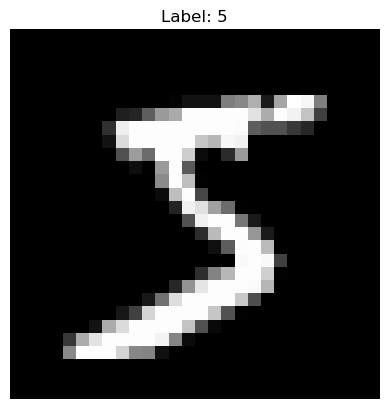

In [40]:
import matplotlib.pyplot as plt

image, label = train_dataset[0]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

# Building the MLP

In [41]:
class MNISTModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )
    def forward(self, x):
        return self.network(x)

In [42]:
# Create
model = MNISTModel()

print(model)


MNISTModel(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [43]:
criterion = nn.CrossEntropyLoss()

In [45]:
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [46]:
# Training Loop
epochs = 5

for epoch in range(epochs):

    model.train()

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    print(
        f"Epoch {epoch+1}, loss: {loss.item():.4f}"
    )

Epoch 1, loss: 0.0421
Epoch 2, loss: 0.1568
Epoch 3, loss: 0.0123
Epoch 4, loss: 0.1232
Epoch 5, loss: 0.1902


In [48]:
# Evaluate the model
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = correct / total
print(f"accuracy: {accuracy:.4f}")

accuracy: 0.9778
